# 08 · Velocidade do meta (D20)

Popularidade de agentes ao longo da janela e quão rápido o meta se reorganiza.

- **Pick rate** de um agente no mês = composições (time × mapa) com o agente ÷ composições do mês.
- **Velocidade** = distância de variação total entre o meta de um mês e o do mês anterior (0 = nada
  mudou), com IC por bootstrap paramétrico e o piso de ruído (a distância que só a amostragem
  produziria). Patches marcados.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from pipeline import analyses as A
from pipeline import plots as P
from pipeline.stats import fmt

P.setup()
pd.set_option("display.precision", 3)
con = A.connect()  # dbt/metascope.duckdb, do `make build`
A.window(con)

{'first_match': '2025-10-16', 'last_match': '2026-10-11'}

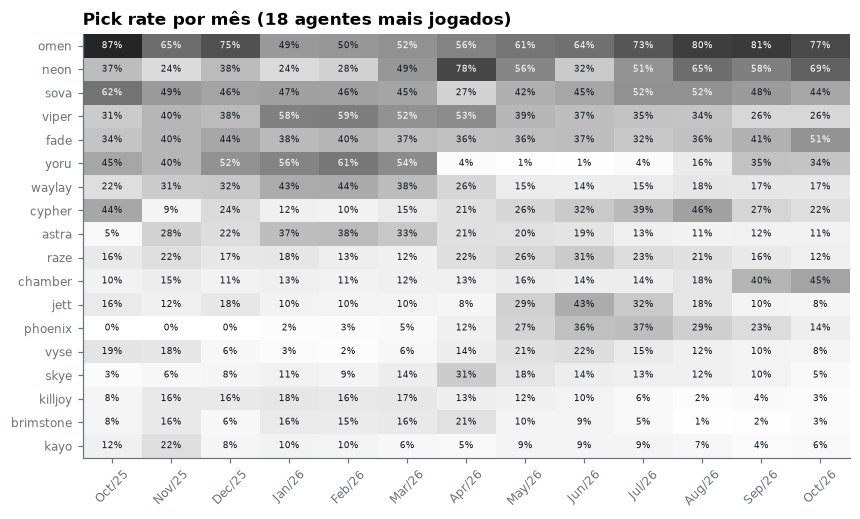

In [2]:
speed = A.meta_speed(con)
pick, sp, patches = speed["pick_rate"], speed["speed"], speed["patches"]
top = pick.mean().sort_values(ascending=False).head(18).index
fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(pick[top].T.values, cmap="Greys", aspect="auto", vmin=0, vmax=1)
ax.set_yticks(range(len(top)), top)
ax.set_xticks(range(len(pick.index)), [pd.Timestamp(m).strftime("%b/%y") for m in pick.index],
              rotation=45)
ax.grid(False)
for i, agent in enumerate(top):
    for j, v in enumerate(pick[agent]):
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=6,
                color="white" if v > 0.5 else P.INK)
ax.set_title("Pick rate por mês (18 agentes mais jogados)")
plt.show()

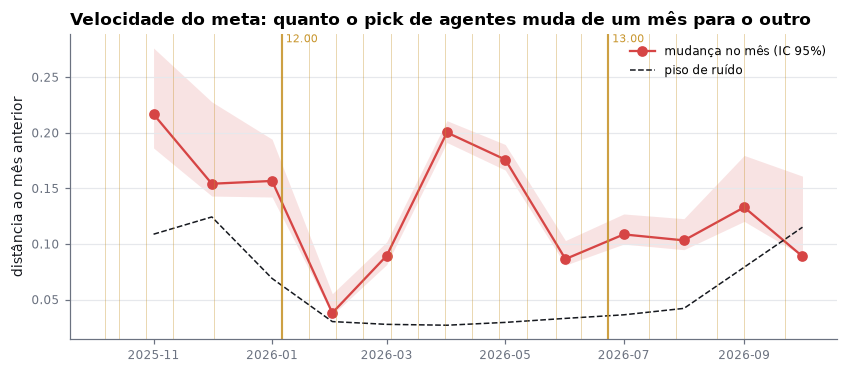

,month,compositions,distance,low,high,noise_floor
0,11/2025,68,0.217,0.186,0.276,0.109
1,12/2025,160,0.154,0.143,0.228,0.124
2,01/2026,1632,0.157,0.142,0.194,0.069
3,02/2026,1604,0.038,0.036,0.055,0.030
4,03/2026,2244,0.089,0.081,0.102,0.028
5,04/2026,1934,0.200,0.191,0.211,0.027
6,05/2026,1630,0.176,0.166,0.189,0.029
7,06/2026,1304,0.086,0.081,0.103,0.033
8,07/2026,1074,0.109,0.100,0.127,0.036
9,08/2026,700,0.103,0.095,0.123,0.042


In [3]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.fill_between(sp.month, sp.low, sp.high, color=P.ATTACK, alpha=0.15, lw=0)
ax.plot(sp.month, sp.distance, "o-", color=P.ATTACK, label="mudança no mês (IC 95%)")
ax.plot(sp.month, sp.noise_floor, color=P.INK, lw=1, ls="--", label="piso de ruído")
for r in patches.itertuples():
    major = r.patch.endswith(".00")
    ax.axvline(pd.Timestamp(r.release_date), color=P.GOLD, lw=1.4 if major else 0.6,
               alpha=0.9 if major else 0.4)
    if major:
        ax.text(pd.Timestamp(r.release_date), ax.get_ylim()[1], f" {r.patch}", fontsize=7,
                color=P.GOLD, va="top")
ax.set_ylabel("distância ao mês anterior")
ax.set_title("Velocidade do meta: quanto o pick de agentes muda de um mês para o outro")
ax.legend(loc="upper right")
P.save(fig, "velocidade-do-meta.png")
plt.show()
sp.assign(month=sp.month.dt.strftime("%m/%Y")).round(3)

## Conclusão

In [4]:
real = sp[sp.low > sp.noise_floor]
full = sp[sp.compositions >= 500]  # fora do off-season
peak = full.loc[full.distance.idxmax()]
first, last = full.month.min(), full.month.max()
delta = (pick.loc[last] - pick.loc[first]).sort_values()
display(Markdown(f"""
- Em **{len(real)} de {len(sp)}** meses a mudança fica acima do piso de ruído (limite inferior do
  IC), ou seja, o meta muda todo mês de forma mensurável. Meses com pouca partida (off-season) têm
  piso alto e não dizem nada.
- Maior reorganização fora do off-season (≥ 500 composições no mês): **{peak.month:%m/%Y}**,
  {fmt(peak.distance, 3)} do meta trocado em relação ao mês anterior
  (IC {fmt(peak.low, 3)}–{fmt(peak.high, 3)}; piso de ruído {fmt(peak.noise_floor, 3)}).
- De {first:%m/%Y} a {last:%m/%Y}, quem mais subiu: {", ".join(f"{a} (+{fmt(v * 100, 0)} p.p.)" for a, v in delta.tail(3)[::-1].items())};
  quem mais caiu: {", ".join(f"{a} ({fmt(v * 100, 0)} p.p.)" for a, v in delta.head(3).items())}.
- Junto com o notebook 00: o meta de um mês já não é o do mês anterior, e em 12 meses se afasta
  bastante. A janela de 12 meses é o teto, não o piso, do que ainda descreve o jogo atual.
"""))


- Em **11 de 12** meses a mudança fica acima do piso de ruído (limite inferior do
  IC), ou seja, o meta muda todo mês de forma mensurável. Meses com pouca partida (off-season) têm
  piso alto e não dizem nada.
- Maior reorganização fora do off-season (≥ 500 composições no mês): **04/2026**,
  0,200 do meta trocado em relação ao mês anterior
  (IC 0,191–0,211; piso de ruído 0,027).
- De 01/2026 a 08/2026, quem mais subiu: neon (+40 p.p.), cypher (+34 p.p.), omen (+31 p.p.);
  quem mais caiu: yoru (-40 p.p.), astra (-26 p.p.), waylay (-26 p.p.).
- Junto com o notebook 00: o meta de um mês já não é o do mês anterior, e em 12 meses se afasta
  bastante. A janela de 12 meses é o teto, não o piso, do que ainda descreve o jogo atual.
